In [311]:
#Example1; Scrapping a real website; 
#Supermart Nigeria Product Price Analysis: Exploring Grocery Prices, Product Categories, and Affordability Using Python Web Scraping
#Step 1: Import the libraries

import requests
from bs4 import BeautifulSoup
import pandas as pd

#requests → Downloads the webpage.
#BeautifulSoup → Reads and understands the HTML.
#pandas → Stores the scraped data in a table (DataFrame).

In [312]:
#Step2 Visit the webpage

url = "https://www.supermart.ng/collections/food-cupboard/"

In [313]:
response = requests.get(url)
#requests.get(url) sends a request to the website.
#The website responds with the HTML of the page.
#That HTML is stored in page.
#Create a variable called url and store the website address inside it.

In [314]:
headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(
    url,
    headers=headers,
    timeout=20
)

In [315]:
print(response.status_code)

200


In [316]:
soup = BeautifulSoup(response.text, "html.parser")

print(soup.title)

# response.text = Gets the website's HTML code.
# BeautifulSoup() = Helps Python read and search the HTML.
# html.parser = Tells BeautifulSoup how to read the HTML.
# soup = Stores the HTML that BeautifulSoup has read.
# soup.title = Finds the website's title.
# print() = Displays the result.

<title>Buy Food Cupboard Products on Supermart.ng | Heinz, Kellogg's, Bama - Supermart.ng</title>


In [317]:
#Find the links on the webpage

links = soup.find_all("a")

print("Total links found:", len(links))

# soup.find_all("a") = Finds all HTML links on the webpage.
# links = Stores all the links found.
# len(links) = Counts how many links were found.
# print() = Displays the total number of links.

Total links found: 403


In [318]:
#Now, what do we do after finding 403 links?
#We need to look inside those links to see where they lead.
#Think of it this way: You found 403 doors inside a supermarket. We don't know which doors lead to products and which lead to other sections.
#So, our next job is to look at the labels on a few doors.

In [319]:
#Display the first 10 links

for link in links[:10]:
    print(link.get("href"))

#links[:10]: Python, give me only the first 10 links out of the 403 links. We're starting with 10 because displaying all 403 at once would be confusing
#for link in links[:10]: Means Python, take those 10 links and examine them one after another.
#link.get("href"): Get the website address stored inside this link

#These first 10 links are not individual product links.
#Most of them lead to menus, categories, or other website pages.


#main-content
https://install.page/supermart
/
/search
https://www.supermart.ng/customer_authentication/redirect?locale=en&region_country=NG
/cart
/collections/uk-groceries
/collections/uk-groceries
/collections/food-pantry
/collections/snacks-treats


In [320]:
#Let's look for product links
#we're looking for links to individual products, such as rice, spaghetti, or cooking oil.

for link in links:
    href = link.get("href")

    if href and "/products/" in href:
        print(href)

# for link in links = Checks all 403 links one by one.
# href = Gets the address of each link.
# if href = Makes sure the link has an address.
# "/products/" in href = Checks for product links.
# print(href) = Displays matching links.

/collections/food-cupboard/products/maharani-organic-honey-300-g-pet-bottle
/collections/food-cupboard/products/maharani-organic-honey-300-g-pet-bottle
/collections/food-cupboard/products/maharani-organic-honey-300-g-pet-bottle
/collections/food-cupboard/products/titus-sardines-125-g
/collections/food-cupboard/products/titus-sardines-125-g
/collections/food-cupboard/products/titus-sardines-125-g
/collections/food-cupboard/products/de-luxe-beans-flour-900-g
/collections/food-cupboard/products/de-luxe-beans-flour-900-g
/collections/food-cupboard/products/de-luxe-beans-flour-900-g
/collections/food-cupboard/products/heinz-baked-beans-200-g
/collections/food-cupboard/products/heinz-baked-beans-200-g
/collections/food-cupboard/products/heinz-baked-beans-200-g
/collections/food-cupboard/products/green-giant-niblets-sweetcorn-340-g
/collections/food-cupboard/products/green-giant-niblets-sweetcorn-340-g
/collections/food-cupboard/products/green-giant-niblets-sweetcorn-340-g
/collections/food-c

In [321]:
#Each link points to a product page.
#For example:
#/collections/food-cupboard/products/titus-sardines-125-g
#We can break it into three parts:
#/collections/ :The website's collection section
#food-cupboard:The grocery category
#/products/titus-sardines-125-g	The individual product
#Why is each product link appearing three times?
#because the webpage contains multiple links pointing to the same product.

In [322]:
#Lets saves the product links
product_links = []

for link in links:
    href = link.get("href")

    if href and "/products/" in href:
        product_links.append(href)

In [323]:
print("Total product links:", len(product_links))

#What this code does: It saves all the product links, including duplicates, and counts them

Total product links: 150


In [324]:
#Remove duplicate product links
#We remove repeated product links to avoid scraping the same product multiple times and creating unnecessary duplicate records.
#Now we're going to keep each product link only once.

unique_products = list(set(product_links))

print("Total unique products:", len(unique_products))


Total unique products: 50


In [325]:
#Let's view our first 5 unique product links
for product in unique_products[:5]:
    print(product)

/collections/food-cupboard/products/kelloggs-corn-flakes-450-g-uk
/collections/food-cupboard/products/skippy-peanut-butter-smooth-creamy-462-g
/collections/food-cupboard/products/indomie-instant-noodles-chicken-70-g
/collections/food-cupboard/products/sipa-couscous-500-g
/collections/food-cupboard/products/kelloggs-corn-flakes-sachet-400-g


In [326]:
#Check whether BeautifulSoup can see the prices

print("₦1,430" in soup.get_text())


True


In [327]:
#Let's find the HTML tag containing that price
price = soup.find(string=lambda text: text and "₦1,430" in text)

print(price.parent)

#soup.find(); Tells BeautifulSoup to search the webpage HTML.
#string=lambda text: text and "₦1,430" in text; Tells Python to look for text containing the price ₦1,430.
#price.parent; Shows the HTML tag surrounding the price

<span class="price__current">₦1,430.00
</span>


In [328]:
#Find all product prices. 
prices = soup.find_all("span", class_="price__current")

print("Total prices found:", len(prices))

#soup.find_all(); Tells BeautifulSoup to find all matching HTML elements.
#"span"; We're looking for <span> tags.
#class_="price__current" We're telling Python to find only those <span> tags with the class price__current.
#prices = Stores everything Python finds in a variable called prices.
#len(prices); Counts how many matching price elements were found.

Total prices found: 50


In [329]:
#Display the first 5 prices
for price in prices[:5]:
    print(price.get_text(strip=True))

#prices[:5]; Tells Python to select only the first five price elements.
#for price in prices[:5]: Tells Python to examine those five prices one after another.
#price.get_text(); Extracts the price text from its HTML tag.
#strip=True: Removes unnecessary spaces and line breaks around the price.
#print(): Displays each price.


₦3,090.00
₦2,185.00
₦5,605.00
₦1,115.00
₦1,430.00


In [330]:
#Lets Find the product names For FoodCupboard Category
#We want to find where Supermart.ng keeps the product names in its HTML, just like we found the prices.

print(prices[0].parent)  #this asks Python: Show me the HTML surrounding the first price.

<div class="price__default">
<span class="price__current">₦3,090.00
</span>
<s class="price__was"></s>
</div>


In [331]:
#prices[0] — selects our first price (₦3,090).
#.parent.parent — looks two levels above the price in the HTML.
#.get_text(" ", strip=True) — shows the readable text there, without the HTML tags.
#print() — displays the result.

print(prices[0].parent.parent.get_text(" ", strip=True))


₦3,090.00 Unit price


In [332]:
print(prices[0].parent.parent.parent.get_text(" ", strip=True))

#I added .parent to the code making it three because i was looking for a bigger HTML section containing both the product name and its price.

Maharani Organic Honey 300 g (Pet Bottle) ₦3,090.00 Unit price


In [333]:
#Identify that HTML section
#i want Python to show me the HTML tag containing this information, so i can understand how to collect the names and prices of all 50 products.

print(prices[0].parent.parent.parent.name)                #.name tells us the HTML tag, such as div.
print(prices[0].parent.parent.parent.get("class"))        #.get("class") tells us the class name of that HTML section

div
['card__info-inner', 'inline-block', 'w-full']


In [334]:
#Find all 50 product information sections (for food cupboard category)

product_cards = soup.find_all("div", class_="card__info-inner")

print("Total product cards found:", len(product_cards))

#soup.find_all(); Tells Python to find all matching HTML elements.
#"div"; Tells Python we're looking for div tags.
#class_="card__info-inner" Tells Python to find the sections containing product information.
#product_cards = Saves those sections so we can use them later.
#len(product_cards) ; Counts how many sections Python found.

Total product cards found: 50


In [335]:
#Display the first 5 products with their prices

for product in product_cards[:5]:
    print(product.get_text(" ", strip=True))

Maharani Organic Honey 300 g (Pet Bottle) ₦3,090.00 Unit price
Titus Sardines 125 g ₦2,185.00 Unit price
De Luxe Beans Flour 900 g ₦5,605.00 Unit price
Heinz Baked Beans 200 g ₦1,115.00 Unit price
Green Giant Niblets Sweetcorn 340 g ₦1,430.00 Unit price


In [336]:
#Find the HTML tag for the product name

print(product_cards[0].prettify()[:1500])

<div class="card__info-inner inline-block w-full">
 <p class="card__title font-bold mt-1 mb-0">
  <a class="card-link text-current js-prod-link" href="/collections/food-cupboard/products/maharani-organic-honey-300-g-pet-bottle">
   Maharani Organic Honey 300 g (Pet Bottle)
  </a>
 </p>
 <div class="price price--sale-color price--top">
  <div class="price__default">
   <span class="price__current">
    ₦3,090.00
   </span>
   <s class="price__was">
   </s>
  </div>
  <div class="unit-price relative" hidden="">
   <span class="visually-hidden">
    Unit price
   </span>
   <span>
   </span>
  </div>
 </div>
</div>



In [337]:
#The two important part of this output is 
#1. Where the product name is stored ; <p class="card__title font-bold mt-1 mb-0">
    #<a class="card-link text-current js-prod-link">
        #Maharani Organic Honey 300 g (Pet Bottle)
    #</a>
#</p>

#2. Where the product price is stored
#<span class="price__current">
    #₦3,090.00
#</span>

In [338]:
#Extract ONE product name and price separately
#Now let's tell Python to collect the name and price from the first product section.

product = product_cards[0]

name = product.find("p", class_="card__title").get_text(strip=True)

price = product.find("span", class_="price__current").get_text(strip=True)

print("Product Name:", name)
print("Price:", price)

Product Name: Maharani Organic Honey 300 g (Pet Bottle)
Price: ₦3,090.00


In [339]:
#Let's extract all 50 product names and prices
#Instead of writing the same code 50 times, we'll use a for loop to do the work automatically.

products = []

for product in product_cards:
    name = product.find("p", class_="card__title").get_text(strip=True)
    price = product.find("span", class_="price__current").get_text(strip=True)

    products.append([name, price])

print("Total products collected:", len(products))

Total products collected: 50


In [340]:
#Create the Food Cupboard Pandas DataFrame

df_food = pd.DataFrame(products, columns=["Product Name", "Price"])

df_food.head()

#pd.DataFrame() This tells Pandas to create a table.
#products; This is the list containing the 50 product names and prices we collected.
#columns=["Product Name", "Price"]; We're giving our table two column headings: Product Name, Price
#df_food = We're saving our table inside a variable called df_food.
#Why df_food? Because this DataFrame contains products from the Food Cupboard category. Later, we can create df_drinks, df_snacks, and other DataFrames.
#df_food.head(); This displays the first five rows of our DataFrame.

,Product Name,Price
0,Maharani Organic Honey 300 g (Pet Bottle),"₦3,090.00"
1,Titus Sardines 125 g,"₦2,185.00"
2,De Luxe Beans Flour 900 g,"₦5,605.00"
3,Heinz Baked Beans 200 g,"₦1,115.00"
4,Green Giant Niblets Sweetcorn 340 g,"₦1,430.00"


In [341]:
#Add a Category column
#we need a Category column cus it will let me know will which product came from which category
#our goal is to scrape different categories from Supermart.ng and combine them into one dataset.

df_food["Category"] = "Food Cupboard"

df_food.head()

,Product Name,Price,Category
0,Maharani Organic Honey 300 g (Pet Bottle),"₦3,090.00",Food Cupboard
1,Titus Sardines 125 g,"₦2,185.00",Food Cupboard
2,De Luxe Beans Flour 900 g,"₦5,605.00",Food Cupboard
3,Heinz Baked Beans 200 g,"₦1,115.00",Food Cupboard
4,Green Giant Niblets Sweetcorn 340 g,"₦1,430.00",Food Cupboard


In [342]:
#Save our Food Cupboard data

df_food.to_csv("food_cupboard.csv", index=False)

print("Food Cupboard data saved successfully!")

Food Cupboard data saved successfully!


In [343]:
#Prepare for our next category; Request the Snacks webpage

url = "https://www.supermart.ng/collections/snacks"

response = requests.get(url, headers=headers, timeout=20)

print(response.status_code)

#url — the address of our Snacks category.
#requests.get() — asks the website to send us the webpage.
#headers=headers — reuses the User-Agent information we used earlier.
#timeout=20 — prevents Python from waiting indefinitely.
#response.status_code — tells us whether the request worked.


200


In [344]:
#Convert the Snacks webpage into BeautifulSoup
#Remember, requests collects the webpage, while BeautifulSoup helps us find information inside it, such as product names and prices.

soup = BeautifulSoup(response.text, "html.parser")

print(soup.title.get_text(strip=True))

Buy Snacks on Supermart.ng | McVities, Pringles, Twix, Oreo, Reelfruit - Supermart.ng


In [345]:
#Find all the Snacks product cards
product_cards = soup.find_all("div", class_="card__info-inner")

print("Total Snacks product cards:", len(product_cards))

#soup.find_all(); Tells BeautifulSoup to search the Snacks webpage.
#"div", class_="card__info-inner" Tells Python which HTML elements contain the product information.
#We're using the same class we discovered when scraping Food Cupboard.
#len(product_cards); Counts how many product cards Python found.

Total Snacks product cards: 50


In [346]:
#Extract the Snacks product names and prices

snacks_products = []

for product in product_cards:
    name = product.find("p", class_="card__title").get_text(strip=True)
    price = product.find("span", class_="price__current").get_text(strip=True)

    snacks_products.append([name, price])

print("Total Snacks products collected:", len(snacks_products))


#snacks_products = []; Creates an empty list where we'll store our Snacks products.
#for product in product_cards:Goes through the 50 product cards one by one.
#name = ...Extracts each product's name.
#price = ... Extracts each product's price.
#snacks_products.append([name, price]); Adds the product name and price together into our list.
#len(snacks_products); Counts how many products we've collected.

Total Snacks products collected: 50


In [347]:
#Let's check for duplicate Snacks products

names = [product[0] for product in snacks_products]

print("Total products:", len(names))
print("Unique product names:", len(set(names)))

#product[0] gets the product name from each [name, price] pair.
#len(names) counts all the products.
#set(names) keeps only unique names.
#len(set(names)) counts those unique names.
#No duplicate product name was found

Total products: 50
Unique product names: 50


In [348]:
#Create our Snacks DataFrame ; Now that we've checked the names, let's arrange our Snacks products into a table.

df_snacks = pd.DataFrame(snacks_products, columns=["Product Name", "Price"])

df_snacks["Category"] = "Snacks"

df_snacks.head()

#df_snacks = pd.DataFrame(...) Creates a DataFrame containing the 50 Snacks products.
#df_snacks["Category"] = "Snacks" Adds a new column called Category and fills it with the word Snacks.
#df_snacks.head() Displays the first five rows.


,Product Name,Price,Category
0,Gratia Chin Chin Flakes 30 g,₦300.00,Snacks
1,Maltesers 37 g,"₦2,150.00",Snacks
2,So Yummy Popcorn Caramel 30 g,₦165.00,Snacks
3,Sky Flakes Crackers 800 g x32,"₦18,445.00",Snacks
4,Lindt Swiss Luxury Selection Assorted Chocolat...,"₦38,920.00",Snacks


In [349]:
#Save our Snacks DataFrame

df_snacks.to_csv("snacks.csv", index=False)

print("Snacks data saved successfully!")

#df_snacks.to_csv(): Saves our Snacks DataFrame as a CSV file.
#"snacks.csv" This is the filename.
#index=False: Prevents Pandas from saving the extra row numbers as a separate column.
#print(): Displays a message confirming that Python reached the end of the saving step.

Snacks data saved successfully!


In [350]:
#Find our third supermarket category
#Request the Drinks webpage

url = "https://www.supermart.ng/collections/drinks"

response = requests.get(url, headers=headers, timeout=20)

print(response.status_code)


200


In [351]:
#Convert the Drinks webpage into BeautifulSoup
#requests retrieves the webpage, while BeautifulSoup helps us find product names and prices inside the HTML.

soup = BeautifulSoup(response.text, "html.parser")

print(soup.title.get_text(strip=True))

#response.text; Contains the HTML code of the Drinks webpage we just retrieved.
#BeautifulSoup(response.text, "html.parser"); Converts that HTML into a format Python can easily search.
#soup = Stores the parsed webpage in a variable called soup.
#soup.title.get_text(strip=True): Extracts the webpage title so we can confirm we're working with the Drinks category.

Buy Drinks on Supermart.ng | Milo, Chivita, Red Bull, Coke, Lipton - Supermart.ng


In [352]:
#Find the Drinks product cards

product_cards = soup.find_all("div", class_="card__info-inner")

print("Total Drinks product cards:", len(product_cards))

#soup.find_all(): Tells BeautifulSoup to search the Drinks webpage.
#"div", class_="card__info-inner" Tells Python to find the HTML sections containing product information.
#len(product_cards) Counts how many product cards Python found.

Total Drinks product cards: 50


In [353]:
#Extract the Drinks product names and prices

drinks_products = []

for product in product_cards:
    name = product.find("p", class_="card__title").get_text(strip=True)
    price = product.find("span", class_="price__current").get_text(strip=True)

    drinks_products.append([name, price])

print("Total Drinks products collected:", len(drinks_products))


Total Drinks products collected: 50


In [354]:
#Check for duplicate Drinks products

names = [product[0] for product in drinks_products]

print("Total Drinks products:", len(names))
print("Unique Drinks product names:", len(set(names)))

#product[0] Each product contains two things: ["Product Name", "Price"], product[0] selects the first item, which is the product name.
#len(names) Counts all the product names we collected.
#set(names); Keeps only unique product names, removing repeated names.
#len(set(names)); Counts how many different product names we have.


Total Drinks products: 50
Unique Drinks product names: 50


In [355]:
#Create our Drinks DataFrame
df_drinks = pd.DataFrame(drinks_products, columns=["Product Name", "Price"])

df_drinks["Category"] = "Drinks"

df_drinks.head()

,Product Name,Price,Category
0,Coca Cola Coke Pet Bottle 50 cl x12,"₦5,880.00",Drinks
1,Dano UHT Full Cream Milk 1 L,"₦3,835.00",Drinks
2,Chivita Active Citrus Mixed Fruit Juice 100 cl,"₦2,210.00",Drinks
3,CWAY Refill Water,"₦2,100.00",Drinks
4,Capri Sun Orange 20 cl x40,"₦14,600.00",Drinks


In [356]:
#Save our Drinks DataFrame

df_drinks.to_csv("drinks.csv", index=False)

print("Drinks data saved successfully!")

Drinks data saved successfully!


In [357]:
#Let's investigate pagination

pagination_links = soup.find_all("a", href=True)

for link in pagination_links:
    if "page=" in link["href"]:
        print(link["href"])
        

/collections/drinks?page=2
/collections/drinks?page=3
/collections/drinks?page=73
/collections/drinks?page=2


In [358]:
#Test page 2 of the Drinks category
url_page2 = "https://www.supermart.ng/collections/drinks?page=2"

response_page2 = requests.get(url_page2, headers=headers, timeout=20)

soup_page2 = BeautifulSoup(response_page2.text, "html.parser")

cards_page2 = soup_page2.find_all("div", class_="card__info-inner")

print("Status code:", response_page2.status_code)
print("Products on page 2:", len(cards_page2))

Status code: 200
Products on page 2: 50


In [359]:
#Are page 1 and page 2 showing different products?
page1_names = set(df_drinks["Product Name"])

page2_names = set()

for product in cards_page2:
    name = product.find("p", class_="card__title").get_text(strip=True)
    page2_names.add(name)

print("Products repeated on both pages:", len(page1_names.intersection(page2_names)))

Products repeated on both pages: 0


In [360]:
#Extract the products from Drinks page 2
drinks_page2 = []

for product in cards_page2:
    name = product.find("p", class_="card__title").get_text(strip=True)
    price = product.find("span", class_="price__current").get_text(strip=True)

    drinks_page2.append([name, price])

print("Products collected from page 2:", len(drinks_page2))


#drinks_page2 = [] Creates an empty list for products from Drinks page 2.
#for product in cards_page2: Goes through each product card on page 2.
#name and price; Extract the product name and price.
#drinks_page2.append([name, price]) Adds each product to our new list.
#len(drinks_page2); Counts how many products we've collected.

Products collected from page 2: 50


In [361]:
#Convert Page 2 Drinks into a DataFrame

df_drinks_page2 = pd.DataFrame(
    drinks_page2,
    columns=["Product Name", "Price"]
)

df_drinks_page2["Category"] = "Drinks"

df_drinks_page2.head()

,Product Name,Price,Category
0,Cowbell Instant Filled Milk Powder Sachet 12 g,₦145.00,Drinks
1,Ribena Ready To Drink Blackcurrant 45 cl,"₦1,230.00",Drinks
2,Wilson's Pink Lemonade 50 cl,"₦1,125.00",Drinks
3,Predator Energy Drink Gold Strike 40 cl x12,"₦7,040.00",Drinks
4,Pocari Sweat Ion Supply Drink Pet 35 cl x24,"₦26,600.00",Drinks


In [362]:
#Combine Page 1 and Page 2

df_all_drinks = pd.concat(
    [df_drinks, df_drinks_page2],
    ignore_index=True
)

print("Total drinks collected:", len(df_all_drinks))

#df_all_drinks This is the name of our new, bigger DataFrame.
#pd.concat(); concat means concatenate, which simply means join things together. We are joining the rows from Page 1 and Page 2.
#[df_drinks, df_drinks_page2]; These are the two tables we want to join.
#ignore_index=True ; Remember that both tables start numbering their rows from 0? This tells Python to give our combined table fresh row numbers:
#0, 1, 2, 3 ... 99
#len(df_all_drinks); This counts how many products are inside our combined DataFrame.

Total drinks collected: 100


In [363]:
#Check our combined DataFrame
df_all_drinks.head()

,Product Name,Price,Category
0,Coca Cola Coke Pet Bottle 50 cl x12,"₦5,880.00",Drinks
1,Dano UHT Full Cream Milk 1 L,"₦3,835.00",Drinks
2,Chivita Active Citrus Mixed Fruit Juice 100 cl,"₦2,210.00",Drinks
3,CWAY Refill Water,"₦2,100.00",Drinks
4,Capri Sun Orange 20 cl x40,"₦14,600.00",Drinks


In [364]:
#Let's check the last 5 products
df_all_drinks.tail()

,Product Name,Price,Category
95,Lords Fermented Original Black Tea 30 g x20,"₦3,290.00",Drinks
96,Eva Table Water 150 cl x12,"₦4,950.00",Drinks
97,Aquafina Premium Drinking Water 150 cl,₦200.00,Drinks
98,Nestle Pure Life Water 150 cl x12,"₦4,560.00",Drinks
99,Girnar Express Chai Instant Tea Pre-Mix 140 g x10,"₦5,050.00",Drinks


In [365]:
#Save our 100 drinks into a CSV file
df_all_drinks.to_csv("all_drinks.csv", index=False)

print("100 drinks saved successfully!")

100 drinks saved successfully!


In [366]:
# Make Python visit the pages automatically

import requests
import pandas as pd
from bs4 import BeautifulSoup
import time

all_new_drinks = []

for page in range(3, 11):

    url = f"https://www.supermart.ng/collections/drinks?page={page}"

    response = requests.get(url, headers=headers, timeout=20)
    print(f"Page {page}: Status {response.status_code}")

    if response.status_code != 200:
        continue

    soup = BeautifulSoup(response.text, "html.parser")

    cards = soup.find_all("div", class_="card__info-inner")

    for product in cards:
        name_tag = product.find("p", class_="card__title")
        price_tag = product.find("span", class_="price__current")

        if name_tag and price_tag:
            name = name_tag.get_text(strip=True)
            price = price_tag.get_text(strip=True)

            all_new_drinks.append([name, price, "Drinks"])

    print("Products collected so far:", len(all_new_drinks))

    time.sleep(2)

df_new_drinks = pd.DataFrame(
    all_new_drinks,
    columns=["Product Name", "Price", "Category"]
)

print("Total new drinks:", len(df_new_drinks))


#Visits Pages 3 to 10 automatically.
#Finds product cards and extracts names and prices.
#Adds each product to one list.
#Converts the list into a DataFrame.
#Displays how many products were collected.

Page 3: Status 200
Products collected so far: 50
Page 4: Status 200
Products collected so far: 100
Page 5: Status 200
Products collected so far: 150
Page 6: Status 200
Products collected so far: 200
Page 7: Status 200
Products collected so far: 250
Page 8: Status 200
Products collected so far: 300
Page 9: Status 200
Products collected so far: 350
Page 10: Status 200
Products collected so far: 400
Total new drinks: 400


In [367]:
#Combine all 500 Drinks products into one table

df_drinks_complete = pd.concat(
    [df_all_drinks, df_new_drinks],
    ignore_index=True
)

print("Total drinks:", len(df_drinks_complete))

print("Duplicate products:",
      df_drinks_complete.duplicated(subset=["Product Name"]).sum())

#pd.concat() joins your two tables together.
#len() counts all the products.
#duplicated() checks whether any product names appear more than once.


Total drinks: 500
Duplicate products: 0


In [368]:
#Save all 500 Drinks products
df_drinks_complete.to_csv("drinks_500.csv", index=False)

print("500 drinks saved successfully!")

500 drinks saved successfully!


In [405]:
#Automatically scrape Fresh- Food Category  Pages 2–10

all_new_food = []                                                 #Create an empty basket

for page in range(2, 11):                           #This is a for loop.It tells Python: "Start from Page 2, visit each page, and stop after Page 10."

    url = f"https://www.supermart.ng/collections/fresh-food?page={page}"        #This creates the website address for each page.

    response = requests.get(url, headers=headers, timeout=20)         #requests.get() sends a request to the website.
                                                                      #url tells Python which page to visit.
                                                                      #headers=headers sends extra information about the request.
                                                                      #timeout=20 tells Python not to wait longer than 20 seconds for a response.
    print(f"Page {page}: Status {response.status_code}")

    if response.status_code != 200:                                   #A status code of 200 means the website responded successfully. The symbol != means not equal to
        continue                                                      #So the if statement means:"If the status code is not 200, skip this page and 
                                                                      #move to the next one."

    soup = BeautifulSoup(response.text, "html.parser")                #Websites are built using HTML. BeautifulSoup helps Python read and search through that HTML.

    cards = soup.find_all("div", class_="card__info-inner")           #Find all the HTML sections containing product information.

    for product in cards:
        name_tag = product.find("p", class_="card__title")             #Extract the product names and prices
        price_tag = product.find("span", class_="price__current")

        if name_tag and price_tag:                                     #If both the product name and price exist, collect them.
            name = name_tag.get_text(strip=True)                       #extracts the text and removes unnecessary spaces.
            price = price_tag.get_text(strip=True)

            all_new_food.append([name, price, "Fresh Food"])

    print("Products collected so far:", len(all_new_food))

    time.sleep(2)

df_new_food = pd.DataFrame(
    all_new_food,
    columns=["Product Name", "Price", "Category"]
)

print("Total new food products:", len(df_new_food))

Page 2: Status 200
Products collected so far: 50
Page 3: Status 200
Products collected so far: 100
Page 4: Status 200
Products collected so far: 150
Page 5: Status 200
Products collected so far: 200
Page 6: Status 200
Products collected so far: 250
Page 7: Status 200
Products collected so far: 300
Page 8: Status 200
Products collected so far: 350
Page 9: Status 200
Products collected so far: 400
Page 10: Status 200
Products collected so far: 450
Total new food products: 450


In [370]:
#Correct the category name

df_new_food["Category"] = "Fresh Food"

print(df_new_food["Category"].unique())

#We're telling Python to change the Category column in df_new_food so every product is labelled "Fresh Food"

[]


In [371]:
#Lets save the 450 Fresh Food products

df_new_food.to_csv("fresh_food.csv", index=False)

print("Fresh Food data saved successfully!")

Fresh Food data saved successfully!


In [372]:
#Scrape Fresh Food Page 1
url = "https://www.supermart.ng/collections/fresh-food?page=1"

response = requests.get(url, headers=headers, timeout=20)

soup = BeautifulSoup(response.text, "html.parser")

cards = soup.find_all("div", class_="card__info-inner")

fresh_food_page1 = []

for product in cards:
    name_tag = product.find("p", class_="card__title")
    price_tag = product.find("span", class_="price__current")

    if name_tag and price_tag:
        name = name_tag.get_text(strip=True)
        price = price_tag.get_text(strip=True)

        fresh_food_page1.append([name, price, "Fresh Food"])

print("Products collected from Page 1:", len(fresh_food_page1))

Products collected from Page 1: 50


In [407]:
#Combine all 500 Fresh Food products into one table

# Convert Page 1 products into a DataFrame
df_fresh_page1 = pd.DataFrame(
    fresh_food_page1,
    columns=["Product Name", "Price", "Category"]
)

# Combine Page 1 with Pages 2–10
df_fresh_food_complete = pd.concat(
    [df_fresh_page1, df_new_food],
    ignore_index=True
)

# Check total products and duplicates
print("Total Fresh Food products:", len(df_fresh_food_complete))

print("Duplicate products:",
      df_fresh_food_complete.duplicated(subset=["Product Name"]).sum())

Total Fresh Food products: 500
Duplicate products: 0


In [409]:
#Save all 500 Fresh Food products

df_fresh_food_complete.to_csv("fresh_food.csv", index=False)

print("500 Fresh Food products saved successfully!")

500 Fresh Food products saved successfully!


In [410]:
#Combine all four categories
#Now i want to put all 1,100 products that i scrapped into one big DataFrame.

df_all_products = pd.concat(
    [df_food, df_snacks, df_drinks_complete, df_fresh_food_complete],
    ignore_index=True
)

print("Total products:", len(df_all_products))

print(df_all_products["Category"].value_counts())



Total products: 1100
Category
Drinks           500
Fresh Food       500
Food Cupboard     50
Snacks            50
Name: count, dtype: int64


In [412]:
df_all_products["Price"].dtype

dtype('O')

In [414]:
df_all_products["Price"] = pd.to_numeric(
    df_all_products["Price"]
    .astype(str)
    .str.replace("₦", "", regex=False)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

print(df_all_products["Price"].dtype)
print("Missing prices:", df_all_products["Price"].isna().sum())

float64
Missing prices: 0


In [415]:
#Next step: Save the complete cleaned dataset

df_all_products.to_csv("supermart_cleaned.csv", index=False)

print("Complete 1,100-product dataset saved successfully!")

Complete 1,100-product dataset saved successfully!


In [376]:
#Data Cleaning — is the process of finding and fixing errors, inconsistencies, and messiness in a dataset before you analyze it.
#Check for Missing Values

df_all_products.isnull().sum()


Product Name    0
Price           0
Category        0
dtype: int64

In [377]:
#Check for duplicate products
df_all_products.duplicated().sum() 

np.int64(0)

In [378]:
#np means NumPy, a Python library.
#int64 means a whole number stored using 64 bits.
#0 is the actual result.
#So np.int64(0) simply means 0, displayed as a NumPy integer


In [379]:
#Check for repeated product names. Note; theres a diff btwn duplicate rows and repeated product names

df_all_products["Product Name"].duplicated().sum()

#This checks whether any product names appear more than once across your entire dataset.


np.int64(0)

In [380]:
#Identify the repeated product
#Before removing anything, let's see which product name appears more than once.

df_all_products[
    df_all_products["Product Name"].duplicated(keep=False)
]

#duplicated() finds repeated product names.
#keep=False tells Pandas to show all occurrences of the repeated name, including the first one.
#df_all_products[...] displays those products with their prices and categories.

,Product Name,Price,Category


In [381]:
#Check our column data types; This will show us the data type of each column.

df_all_products.dtypes

Product Name    object
Price           object
Category        object
dtype: object

In [382]:
#Why is Price showing object?
#Because the prices contain the naira symbol (₦) and commas(₦6,170.00"), Python treats this as text, not a number.

In [387]:
#Convert Price to a number

df_all_products["Price"] = pd.to_numeric(
    df_all_products["Price"]
    .astype(str)
    .str.replace("₦", "", regex=False)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

#.str.replace("₦", "") removes the naira symbol.
#.str.replace(",", "") removes commas.
#pd.to_numeric() converts the remaining text into numbers.
#errors="coerce" turns any price that cannot be converted into a missing value (NaN).
#.head() displays the first five converted prices.

In [391]:
df_all_products["Price"].head()

0    3090.0
1    2185.0
2    5605.0
3    1115.0
4    1430.0
Name: Price, dtype: float64

In [ ]:
# Display the first five prices after cleaning.
# This confirms that the naira symbols and commas have been removed.
# The prices are now stored as numeric values (float64), ready for analysis.

In [388]:
df_all_products["Price"].isnull().sum()

#This checks whether any prices became missing values during conversion.

np.int64(0)

In [393]:
#Save our cleaned dataset

df_all_products.to_csv("supermart_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

#to_csv() saves our DataFrame as a CSV file.
#"supermart_cleaned.csv" is the filename.
#index=False prevents Pandas from saving the row numbers as an extra column.

Cleaned dataset saved successfully!


In [394]:
df_all_products.dtypes

Product Name     object
Price           float64
Category         object
dtype: object

In [246]:
#Introduction to Exploratory Data Analysis (EDA)
#Exploratory Data Analysis means examining a dataset to discover patterns, trends, relationships, and useful information.
#Objective: To analyse product prices across four supermarket categories, identify pricing patterns, and discover useful insights.
#Our proposed research questions
#No.	Business / Research Question	                             Metric or Technique
#How many products were collected from Supermart?	              Count
#What is the average price of products?	                          Mean
#What is the middle price of products?	                          Median
#What is the most frequently occurring product price?	          Mode
#What are the cheapest and most expensive product prices?	      Minimum and Maximum
#How much do product prices vary?	                              Standard Deviation
#Which category has the highest average product price?	          GroupBy + Mean
#Which category has the lowest average product price?	          GroupBy + Mean
#How are products distributed across categories?	                  Count + Percentage
#Are there unusually expensive or cheap products?	              Outlier Detection
#What is the price range within each category?	                  GroupBy + Min/Max
#Which products are the five most expensive and five cheapest?     Sorting

In [247]:
#Research Question 1
#How many product records were collected from Supermart Nigeria?
#Metric: Total Product Count  i.e What measurement will give me the answer?
#Technique: count()            i.e What method will I use to calculate or investigate it?

In [249]:
total_products = df_all_products["Product Name"].count()

print("Total Products:", total_products)

#df_all_products — our cleaned dataset.
#["Product Name"] — selects the Product Name column.
#.count() — counts the non-missing product names.
#total_products — stores the result.
#print() — displays the result.

Total Products: 1100


In [250]:
#Insight: The dataset contains 1,100 product records collected from four Supermart Nigeria categories: Drinks, Fresh Food, Food Cupboard, and Snacks.

In [252]:
#Research Question 2
#What is the average price of products collected from Supermart Nigeria?
#Metric: Average Product Price 
#Pandas Technique: .mean()

average_price = df_all_products["Price"].mean()

print("Average Product Price:", average_price)

Average Product Price: 7810.464545454545


In [253]:
#Insight
#The average product price across the 1,100 Supermart product records analysed is approximately ₦7,810.46. 
#This provides a general benchmark for understanding product prices in the collected dataset.

In [255]:
#Research Question 3: What is the median product price?
#The median is the middle price when all product prices are arranged from lowest to highest.

median_price = df_all_products["Price"].median()

print("Median Product Price:", median_price)

Median Product Price: 2877.5


In [256]:
#Insight
#The median product price is ₦2,877.50, considerably lower than the average price of ₦7,810.46. This suggests that the product price distribution
#is right-skewed, with relatively expensive products increasing the overall average.

In [258]:
sorted_prices = df_all_products["Price"].sort_values().reset_index(drop=True)

print("550th Price:", sorted_prices.iloc[549])
print("551st Price:", sorted_prices.iloc[550])

550th Price: 2875.0
551st Price: 2880.0


In [260]:
#Research Question 4 — Mode
#What is the most frequently occurring product price?

mode_price = df_all_products["Price"].mode()

print("Most Frequent Product Price:", mode_price)

Most Frequent Product Price: 0    365.0
Name: Price, dtype: float64


In [261]:
#0 — the index of the result, not the product price.
#365.0 — the mode, meaning ₦365 is the most frequently occurring price.
#Name: Price — the column we analysed.
#dtype: float64 — the result is numerical.
#Insight 
#The most frequently occurring product price in the collected Supermart dataset is ₦365.00, indicating that this price appears more often 
#than any other individual price.

In [263]:
#How many times does ₦365 appear in our dataset?
price_frequency = df_all_products["Price"].value_counts()

print(price_frequency.head())

Price
365.0     68
1400.0    12
1600.0    11
240.0      9
4620.0     8
Name: count, dtype: int64


In [265]:
#₦365 is the most frequently occurring product price, appearing in 68 out of 1,100 records (6.18%). 
#This is considerably more frequent than the next most common price, ₦1,400, which appears 12 times.
#To identify best-selling products, we would need sales data, such as quantities sold.

df_all_products[df_all_products["Price"] == 365]["Category"].value_counts()

Category
Fresh Food    68
Name: count, dtype: int64

In [266]:
#Insight for the most frequently occuring product price(365)
#The most frequently occurring product price is ₦365, appearing 68 times exclusively within the Fresh Food category. 
#This suggests a concentration of products at this price point within the sampled Fresh Food listings.

#Recommendation: Examine the product names to understand whether these are different products, variations of similar products, or items sharing a common price.
#Let's see which products cost ₦365

In [268]:
df_all_products[df_all_products["Price"] == 365][
    ["Product Name", "Price", "Category"]
].head(10)

,Product Name,Price,Category
875,Bauer Fru Fru Yoghurt Raspberry 100 g,365.0,Fresh Food
876,Alpro Yoghurt Plain 400 g,365.0,Fresh Food
877,Onken Yoghurt Cherry 400 g,365.0,Fresh Food
880,Onken Yoghurt Natural 400 g,365.0,Fresh Food
881,Fage TruBlend Coconut 150 g,365.0,Fresh Food
885,Onken Yoghurt Strawberry 1 kg,365.0,Fresh Food
886,Onken Yoghurt Raspberry 400 g,365.0,Fresh Food
887,Fage TruBlend Blueberry 150 g,365.0,Fresh Food
891,Fage TruBlend Strawberry 150 g,365.0,Fresh Food
892,Alpro Yoghurt Strawberry 400 g,365.0,Fresh Food


In [270]:
products_365 = df_all_products[df_all_products["Price"] == 365]

print(products_365["Product Name"].to_string(index=False))

             Bauer Fru Fru Yoghurt Raspberry 100 g
                         Alpro Yoghurt Plain 400 g
                        Onken Yoghurt Cherry 400 g
                       Onken Yoghurt Natural 400 g
                       Fage TruBlend Coconut 150 g
                     Onken Yoghurt Strawberry 1 kg
                     Onken Yoghurt Raspberry 400 g
                     Fage TruBlend Blueberry 150 g
                    Fage TruBlend Strawberry 150 g
                    Alpro Yoghurt Strawberry 400 g
                   Pinar Labne Multi-Pack 160 g x8
                   Dolait Yoghurt Apricot 125 g x4
                   Monfruit Yoghurt Peach 125 g x4
                  Yeo Valley Yoghurt Vanilla 400 g
                  Alpro Yoghurt Plain Almond 400 g
                  Monfruit Yoghurt Banana 125 g x4
                 Monfruit Yoghurt Natural 125 g x4
                 Alpro Yoghurt Plain Coconut 400 g
                 Actimel Immune Support Coconut x8
                Yeo Valley Yogh

In [272]:
#Research Question 5: What are the minimum and maximum product prices?
#We're simply finding the cheapest and most expensive prices in our dataset.
minimum_price = df_all_products["Price"].min()

maximum_price = df_all_products["Price"].max()

print("Minimum Product Price:", minimum_price)
print("Maximum Product Price:", maximum_price)

Minimum Product Price: 90.0
Maximum Product Price: 980000.0


In [274]:
#Let's investigate which products have these prices

df_all_products[
    df_all_products["Price"].isin([90, 980000])
]

#df_all_products["Price"] selects the Price column.
#.isin([90, 980000]) checks whether each price is either ₦90 or ₦980,000.
#df_all_products[...] displays the matching product records, including their names, prices, and categories.

,Product Name,Price,Category
447,California Sun Fruits Cocktail Juice 15 cl,90.0,Drinks
689,Ginger (Fresh) - Full Bag,980000.0,Fresh Food


In [275]:
#Insight
#Product prices in the Supermart dataset range from ₦90 to ₦980,000, representing a price difference of ₦979,910. The wide range indicates substantial
#variation in product prices, with the highest recorded price belonging to a full bag of fresh ginger.

#Recommendation
#The business could analyse prices separately by product category and package size to make comparisons more meaningful.
#Also, the ₦980,000 ginger listing deserves verification because unusually high prices can strongly influence the average.

In [277]:
#Find the 10 most expensive products
#How does the ₦980,000 ginger price compare with the other highest product prices?
top_10_expensive = df_all_products.nlargest(10, "Price")

top_10_expensive[["Product Name", "Price", "Category"]]

,Product Name,Price,Category
689,Ginger (Fresh) - Full Bag,980000.0,Fresh Food
854,Ram - Live (Medium),590000.0,Fresh Food
686,Irish Potato - Full Bag,220000.0,Fresh Food
685,Irish Potato - Half Bag,112000.0,Fresh Food
699,Onions - Red Onions - Half Bag,95000.0,Fresh Food
844,Chicken Breast ~10 kg,90900.0,Fresh Food
713,Whole Fresh Salmon ~1.8 kg,90190.0,Fresh Food
692,Irish Potato - Quarter Bag,89500.0,Fresh Food
166,WellMan Can Drink 25 cl x24,86645.0,Drinks
845,Smoked Salmon 1 kg,85700.0,Fresh Food


In [278]:
#Preliminary insight
#The highest-priced product is Ginger (Fresh) - Full Bag at ₦980,000, substantially exceeding the second-highest price of ₦590,000. 
#Nine of the ten most expensive product records belong to the Fresh Food category, suggesting that bulk and high-value items contribute to the upper
#end of the price distribution.

In [280]:
#Let's identify outliers using IQR
#IQR stands for Interquartile Range. It helps us identify prices that are unusually far from the middle portion of our data.

Q1 = df_all_products["Price"].quantile(0.25)

Q3 = df_all_products["Price"].quantile(0.75)

print("Q1:", Q1)
print("Q3:", Q3)

Q1: 990.0
Q3: 6623.75


In [ ]:
#Understanding Q1 and Q3
#Measure	Your Result	Meaning
#Q1 (25th percentile)	₦990.00	Approximately 25% of product records have prices at or below ₦990
#Q3 (75th percentile)	₦6,623.75	Approximately 75% of product records have prices at or below ₦6,623.75
#This means the middle 50% of your product prices lie approximately between ₦990 and ₦6,623.75.

In [282]:
#Calculate the IQR
#IQR stands for Interquartile Range.
#It measures the spread of the middle 50% of our product prices.

IQR = Q3 - Q1

print("Interquartile Range:", IQR)

Interquartile Range: 5633.75


In [284]:
#: Calculate the upper outlier boundary
#Now we want to answer one question:
#Is the ₦980,000 ginger price unusually high according to the IQR method?

upper_boundary = Q3 + (1.5 * IQR)

print("Upper Outlier Boundary:", upper_boundary)

Upper Outlier Boundary: 15074.375


In [286]:
#Using the IQR method, any product price above ₦15,074.38 is considered a potential high-price outlier.
#How many products are outliers?
#Now let's find out how many of our 1,100 product records have prices above the upper boundary.

high_price_outliers = df_all_products[
    df_all_products["Price"] > upper_boundary
]

print("Number of High-Price Outliers:", len(high_price_outliers))


#df_all_products["Price"] > upper_boundary checks which prices exceed ₦15,074.38.
#df_all_products[...] selects those product records.
#high_price_outliers stores the selected records.
#len() counts how many records were selected.

Number of High-Price Outliers: 88


In [287]:
#Insight for your capstone project
#The IQR analysis identified 88 high-price outliers, representing 8% of the dataset. These products have prices above ₦15,074.38, 
#indicating a group of unusually high-priced listings relative to the overall product price distribution.

In [289]:
#Let's find out which categories contain these 88 high-price outliers.

high_price_outliers["Category"].value_counts()

Category
Fresh Food       53
Drinks           30
Food Cupboard     3
Snacks            2
Name: count, dtype: int64

In [290]:
#Insight
#The IQR analysis identified 88 high-price outliers, representing 8% of the 1,100 product records. Fresh Food accounted for 53 of these outliers and 
#had the highest within-category outlier rate at 10.6%. This suggests that unusually high prices are more prevalent among the sampled Fresh Food listings.

#Recommendation: When comparing product prices, consider differences in product type and package size. High-priced bulk products should not 
#automatically be treated as pricing errors.

In [292]:
#Research Question 6
#How much do product prices vary across the dataset?

price_std = df_all_products["Price"].std()

print("Standard Deviation:", price_std)

Standard Deviation: 36728.51618720215


In [293]:
#The standard deviation is much higher than the mean because product prices vary considerably across the dataset, with some products costing much 
#more than others. These unusually high prices increase the overall spread of the data.


#What is standard deviation?
#Standard deviation measures how spread out the prices are from the average price (mean).
#A small standard deviation means prices are generally close to the average.
#A large standard deviation means prices are widely spread out.

#Insight for your capstone report
#The standard deviation of product prices was ₦36,728.52, substantially higher than the mean price of ₦7,810.46. This indicates considerable price 
#variation across the sampled Supermart products. The presence of high-priced products, including bulk Fresh Food items, contributes to this variation.

#Recommendation: Use the median alongside the mean when reporting typical product prices, because unusually expensive products can pull the mean upward.

In [295]:
#Research Question 7: Which product category has the highest average price?
#Now we'll use groupby()

category_average_price = df_all_products.groupby("Category")["Price"].mean()

print(category_average_price)

Category
Drinks            5516.210
Food Cupboard     5688.000
Fresh Food       10709.782
Snacks            3882.300
Name: Price, dtype: float64


In [296]:
#Insight for my capstone report
#Fresh Food recorded the highest average product price at ₦10,709.78, followed by Food Cupboard at ₦5,688.00, Drinks at ₦5,516.21, and 
#Snacks at ₦3,882.30. High-priced bulk products may contribute to Fresh Food's higher average.

#Recommendation: 
#Compare average and median prices by category to better understand typical pricing, particularly where expensive bulk products influence the average.
#Also, our sample contains 500 Fresh Food records and 500 Drinks records, but only 50 each for Food Cupboard and Snacks. 
#These results describe my collected sample, not necessarily Supermart's entire inventory.


In [297]:
#Research Question 8: Which product category has the lowest average price?
#Snacks has the lowest average price at ₦3,882.30. Based on the result i got earlier
#Insight: Snacks recorded the lowest average product price at ₦3,882.30 among the four categories analysed. 
#This suggests that Snacks products were generally less expensive on average within the collected dataset. 
#However, only 50 Snacks products were sampled, so this finding may not represent the pricing of all Snacks products available on Supermart.

In [299]:
#Research Question 9: How are the 1,100 product records distributed across the four categories?
#We want to know how many product records we collected from each category

category_counts = df_all_products["Category"].value_counts()

print(category_counts)

Category
Drinks           500
Fresh Food       500
Food Cupboard     50
Snacks            50
Name: count, dtype: int64


In [300]:
#Insight for my capstone report
#The dataset contains 1,100 product records across four categories. Drinks and Fresh Food each account for 45.45% of the collected records, 
#while Food Cupboard and Snacks each represent 4.55%. This uneven distribution reflects the data collection process and should be considered 
#when interpreting category-level findings.

In [302]:
#Calculate the percentages using Python

category_percentages = (
    df_all_products["Category"].value_counts(normalize=True) * 100
)

print(category_percentages.round(2))

#What does normalize=True mean?
#Instead of returning the number of products, it returns each category's proportion of the total. Multiplying by 100 converts that proportion 
#into a percentage.

Category
Drinks           45.45
Fresh Food       45.45
Food Cupboard     4.55
Snacks            4.55
Name: proportion, dtype: float64


In [304]:
#Research Question 10: Which products have unusually high or low prices?
#Calculate the lower outlier boundary

lower_boundary = Q1 - (1.5 * IQR)

print("Lower Outlier Boundary:", lower_boundary)

Lower Outlier Boundary: -7460.625


In [305]:
#What does this mean?
#Our IQR method identifies low-price outliers as prices below −₦7,460.63.
#But remember:
#Our cheapest product costs ₦90.
#Product prices in our dataset are all positive.
#₦90 is greater than −₦7,460.63.
#Therefore, there are no low-price outliers according to the IQR method.

In [306]:
#Insight for my capstone report
#The IQR analysis identified 88 high-price outliers, representing 8% of the dataset, and no low-price outliers. 
#Fresh Food contained the largest number of high-price outliers (53). These findings suggest that the price distribution contains unusually 
#expensive products, although these prices may reflect differences in product type and package size rather than data errors.

In [308]:
#Research Question
#Which product category has the highest and lowest median price?

category_median_price = df_all_products.groupby("Category")["Price"].median()

print(category_median_price)

#groupby("Category") separates products into their four categories.
#["Price"] selects the price column.
#.median() calculates the middle price within each category.

Category
Drinks           2980.0
Food Cupboard    3975.0
Fresh Food       2627.5
Snacks           2465.0
Name: Price, dtype: float64


In [ ]:
#Insight: Mean and Median Price Comparison
#Fresh Food recorded the highest average price at ₦10,709.78 but had a considerably lower median price of ₦2,627.50. In contrast,
#Food Cupboard had the highest median price of ₦3,975.00. This indicates that high-priced products, particularly bulk items, 
#strongly influence the Fresh Food average. Therefore, median prices provide a useful additional measure when comparing typical product prices
#across categories.

<Figure size 1000x600 with 0 Axes>

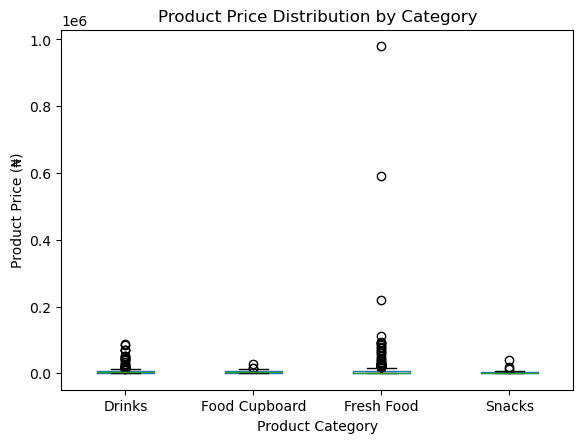

In [416]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

df_all_products.boxplot(
    column="Price",
    by="Category",
    grid=False
)

plt.title("Product Price Distribution by Category")
plt.suptitle("")
plt.xlabel("Product Category")
plt.ylabel("Product Price (₦)")

plt.show()


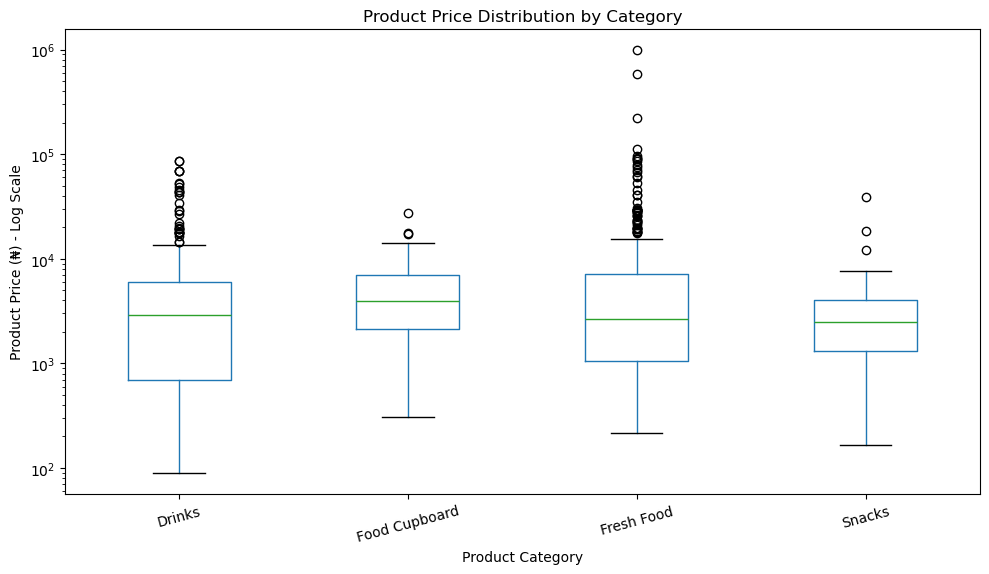

In [417]:
import matplotlib.pyplot as plt

ax = df_all_products.boxplot(
    column="Price",
    by="Category",
    figsize=(10, 6),
    grid=False
)

ax.set_yscale("log")

plt.title("Product Price Distribution by Category")
plt.suptitle("")
plt.xlabel("Product Category")
plt.ylabel("Product Price (₦) - Log Scale")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [419]:
#Let's interpret the chart like a Data Analyst
#Drinks: Product prices vary considerably, with several high-priced outliers.
#Food Cupboard: The middle 50% of product prices appear more concentrated than in Drinks and Fresh Food.
#Fresh Food: This category contains the most extreme high-priced outliers, including a product priced around ₦980,000.
#Snacks: Prices appear relatively concentrated, although a few higher-priced outliers are visible.
#The green horizontal line inside each box represents the median price.
#The blue box represents the middle 50% of product prices.
#The black circles outside the whiskers represent potential outliers.

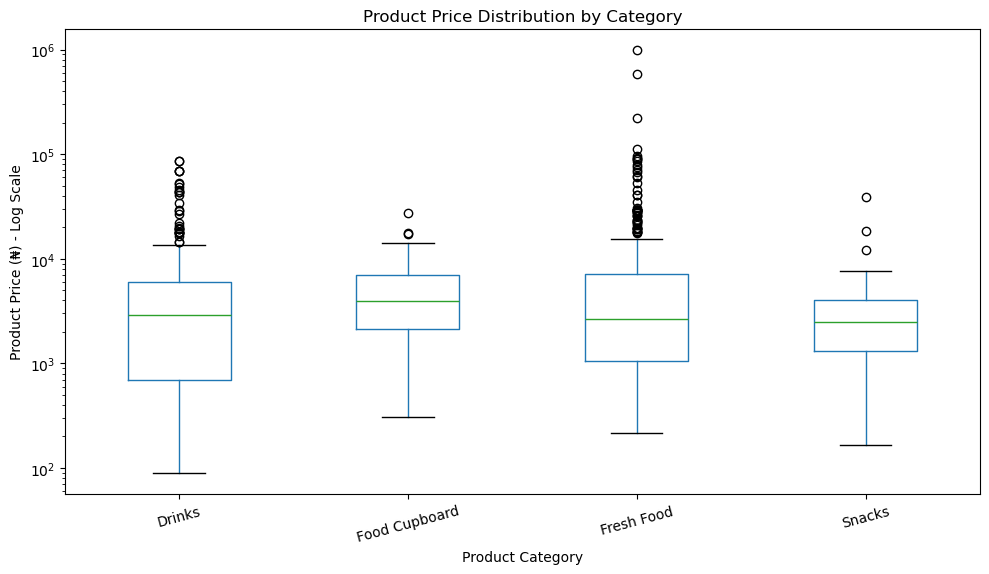

In [420]:
ax = df_all_products.boxplot(
    column="Price",
    by="Category",
    figsize=(10, 6),
    grid=False
)

ax.set_yscale("log")
plt.title("Product Price Distribution by Category")
plt.suptitle("")
plt.xlabel("Product Category")
plt.ylabel("Product Price (₦) - Log Scale")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig("supermart_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()
